# Lecture 9: Quantum Teleportation and Grover Search

[Course contents](../00_course_contents.md) | [← Previous lecture](./08_quantum_circuits_with_qiskit.ipynb) | [Next lecture →](./10_quantum_algorithms.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Derive the three-qubit teleportation identity and account for its entanglement and classical-communication resources.
- Explain why teleportation obeys no signaling and how experimental teleportation fidelity is assessed.
- Build phase oracles and interpret Grover search as a rotation in a two-dimensional subspace.
- Distinguish oracle-query complexity from complete circuit and data-loading cost.

## Core ideas

- **Teleportation transfers an unknown quantum state, not matter, using one shared ebit and two classical bits.**
- **The receiver's state is not usable until the classical correction information arrives, so no signaling is violated.**
- **Grover search is a controlled rotation.** Its quadratic query advantage does not erase oracle construction, loading, routing, or error-correction cost.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from sympy import sqrt, symbols, Rational
from sympy import expand, Eq, Symbol, simplify, exp, sin
from sympy.physics.quantum import *
from sympy.physics.quantum.qubit import *
from sympy.physics.quantum.gate import *
from sympy.physics.quantum.grover import *
from sympy.physics.quantum.qft import QFT, IQFT, Fourier
from sympy.physics.quantum.circuitplot import circuit_plot
from sympy.physics.quantum import TensorProduct
from IPython.core.interactiveshell import InteractiveShell
from sympy.physics.quantum.qubit import IntQubit

**Recorded lecture: quantum teleportation**

[Watch the recorded lecture on quantum teleportation](https://www.youtube.com/watch?v=NGxfP93iN4w).

**Recorded lecture: Grover search and amplitude amplification**

[Watch the recorded lecture on Grover search and amplitude amplification](https://www.youtube.com/watch?v=isWP5Rg-Me4).

In [2]:
#Activate multiple output
InteractiveShell.ast_node_interactivity = "all"

## From amplitudes to algorithms

An $N$-qubit pure state has the form

$$
|\psi\rangle=\sum_{x\in\{0,1\}^N}\alpha_x|x\rangle,
\qquad \sum_x|\alpha_x|^2=1.
$$

This compact physical state is not a readable table of $2^N$ classical answers. One measurement returns one $N$-bit string, distributed according to $|\alpha_x|^2$. Quantum algorithms therefore have to arrange **interference** so that useful outcomes have large probability and unhelpful outcomes have small probability.

Entanglement supplies correlations that cannot be represented by independent one-qubit states, but it neither sends information faster than light nor guarantees a computational speedup. A speedup is always relative to a specified problem, input encoding, computational model, error criterion, and classical comparison algorithm.

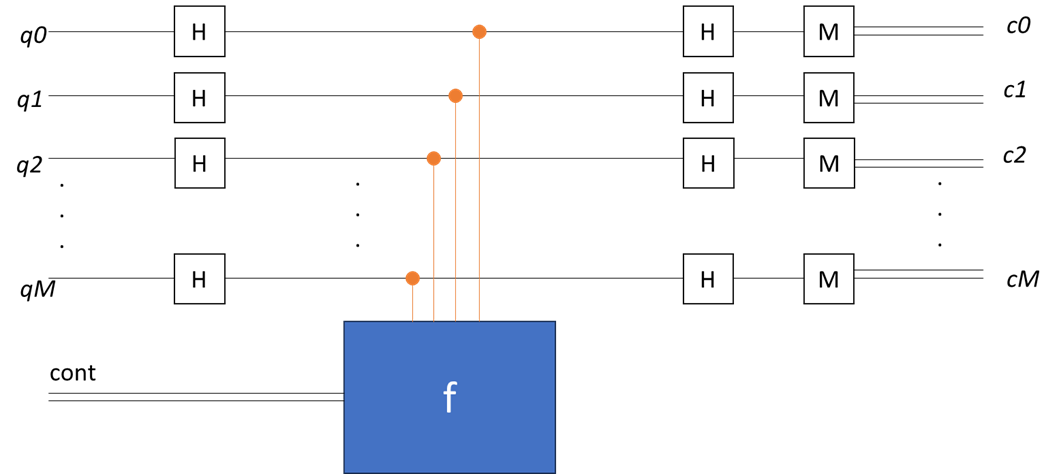

## Quantum teleportation

The **no-cloning theorem** says that no physical operation can copy every unknown state while leaving the input unchanged. A unitary satisfying

$$U|\psi\rangle|0\rangle=|\psi\rangle|\psi\rangle$$

for every $|\psi\rangle$ would fail to preserve inner products for nonorthogonal inputs. Orthogonal states can be copied, and a known state can be prepared again; the prohibition concerns a universal copier for arbitrary unknown states.

Quantum teleportation transfers an unknown state by consuming shared entanglement and sending classical information. The input qubit is measured and its original state is destroyed, so the protocol does not clone it.

Primary sources: W. K. Wootters and W. H. Zurek, [“A single quantum cannot be cloned”](https://doi.org/10.1038/299802a0) (1982); C. H. Bennett *et al.*, [“Teleporting an unknown quantum state via dual classical and Einstein–Podolsky–Rosen channels”](https://doi.org/10.1103/PhysRevLett.70.1895) (1993).

## Teleportation identity, resources, and no signaling

Let the input be $|\psi\rangle_0=\alpha|0\rangle+\beta|1\rangle$ and let Alice and Bob share $|\Phi^+\rangle_{12}=(|00\rangle+|11\rangle)/\sqrt2$. After Alice applies CNOT$_{0\rightarrow1}$ and $H_0$,

$$
(H_0\,\mathrm{CNOT}_{0\rightarrow1})
|\psi\rangle_0|\Phi^+\rangle_{12}
=\frac12\sum_{m_0,m_1\in\{0,1\}}
|m_0m_1\rangle_{01}\,Z^{m_0}X^{m_1}|\psi\rangle_2,
$$

where the $m_0=m_1=1$ branch is understood up to a global phase. Alice measures $m_0m_1$ and sends both bits to Bob; Bob applies $X^{m_1}Z^{m_0}$.

| Alice's bits $(m_0m_1)$ | Bob before correction | Bob applies |
|---|---|---|
| 00 | $\lvert\psi\rangle$ | $I$ |
| 01 | $X\lvert\psi\rangle$ | $X$ |
| 10 | $Z\lvert\psi\rangle$ | $Z$ |
| 11 | $ZX\lvert\psi\rangle$ | $XZ$ |

The protocol consumes one shared Bell pair and sends two classical bits for one input qubit. It does not transmit matter or usable information instantaneously. Before Bob receives the bits, his state is

$$
\rho_B=\frac14\sum_{m_0,m_1}Z^{m_0}X^{m_1}\rho
X^{m_1}Z^{m_0}=\frac{I}{2},
$$

which is independent of the unknown input $\rho$. This is the no signaling mechanism in the teleportation protocol.

### Two-qubit algebra warm-up — not a teleportation protocol

The following SymPy cells illustrate how CNOT and Hadamard gates redistribute amplitudes in a two-qubit state. They are an algebra warm-up, not a teleportation protocol: no independent Bell pair is shared by Alice and Bob, there are not four Bell-measurement branches, and the map is not shown to reproduce every unknown input. The complete three-qubit protocol follows below.

In [3]:
alpha, beta = symbols('alpha, beta')
state_A = Qubit('0')*alpha + Qubit('1')*beta
state_B = Qubit('0')

state_A
state_B

alpha*|0> + beta*|1>

|0>

In [4]:
state = Qubit('00')*alpha + Qubit('10')*beta

state

alpha*|00> + beta*|10>

In [5]:
entangle = CNOT(1,0)
circuit_plot(entangle, nqubits=2);

In [6]:
Shared_state = qapply(entangle*state)
Shared_state

alpha*|00> + beta*|11>

In [7]:
circuit_plot(HadamardGate(1)*entangle, nqubits=2);

In [8]:
New_state = qapply(HadamardGate(1)*Shared_state).simplify()
New_state

sqrt(2)*(alpha*|00> + alpha*|10> + beta*|01> - beta*|11>)/2

### Three-qubit teleportation circuit

**1. Allocate the registers.** Qubit `q[0]` is Alice's input, `q[1]` is Alice's half of an entangled pair, and `q[2]` is Bob's half. The protocol works for any input $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$; the executable example chooses $|1\rangle$ so its final measurement is easy to check.

In [9]:
qr = QuantumRegister(3)  # Initialize qubits
cr0 = ClassicalRegister(1)
cr1 = ClassicalRegister(1)
cr2 = ClassicalRegister(1)
circuit = QuantumCircuit(qr, cr0, cr1, cr2)

circuit.draw('mpl')

<Figure size 180.108x535.111 with 1 Axes>

In [10]:
state = Statevector.from_int(0, 2**3)
state.draw('latex')

<IPython.core.display.Latex object>

**2. Prepare the demonstration input.** Applying $X$ to `q[0]` selects $|\psi\rangle=|1\rangle$. To test a general known state, replace this gate with a state-preparation rotation while leaving the teleportation circuit unchanged.

In [11]:
# Prepare the initial state which we want to transfer
circuit.x(qr[0])
circuit.barrier()

circuit.draw('mpl')

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q0"), index=0>, <Qubit register=(3, "q0"), index=1>, <Qubit register=(3, "q0"), index=2>), clbits=())

<Figure size 305.525x535.111 with 1 Axes>

In [12]:
# Recompute the state after input-state preparation.
state = Statevector.from_instruction(circuit)
state.draw('latex')

<IPython.core.display.Latex object>

**3. Distribute one Bell pair.** Applying $H$ to `q[1]` and CNOT from `q[1]` to `q[2]` prepares

$$|\Phi^+\rangle_{12}=\frac{|00\rangle+|11\rangle}{\sqrt2}.$$

In a network, this entangled pair must be created and verified before Alice's Bell measurement; the local circuit below prepares it directly for clarity.

In [13]:
# Prepare the Bell pair
circuit.h(qr[1])
circuit.cx(qr[1], qr[2])
circuit.barrier()

circuit.draw('mpl')

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q0"), index=0>, <Qubit register=(3, "q0"), index=1>, <Qubit register=(3, "q0"), index=2>), clbits=())

<Figure size 556.358x535.111 with 1 Axes>

In [14]:
# Recompute the state after Bell-pair preparation.
state = Statevector.from_instruction(circuit)
state.draw('latex')

<IPython.core.display.Latex object>

**4. Rotate into the Bell-measurement basis.** CNOT from the input `q[0]` to `q[1]`, followed by $H$ on `q[0]`, maps the four Bell states to distinct computational-basis outcomes. The gates do not perform the measurement by themselves; they change the basis in which the next measurements are made.

In [15]:
# Measure in the Bell basis
circuit.cx(qr[0], qr[1])
circuit.h(qr[0])
circuit.barrier()

circuit.draw('mpl')

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q0"), index=0>, <Qubit register=(3, "q0"), index=1>, <Qubit register=(3, "q0"), index=2>), clbits=())

<Figure size 807.192x535.111 with 1 Axes>

In [16]:
# Recompute the state after the Bell-basis rotation.
state = Statevector.from_instruction(circuit)
state.draw('latex')

<IPython.core.display.Latex object>

**5. Measure Alice's two qubits.** The results $m_0,m_1\in\{0,1\}$ are individually random and reveal no classical description of $\alpha$ or $\beta$. Together they select the Pauli frame needed to recover the input state on Bob's qubit.

In [17]:
circuit.measure(qr[0], cr0[0])
circuit.measure(qr[1], cr1[0])
circuit.barrier()

circuit.draw('mpl')

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q0"), index=0>, <Qubit register=(3, "q0"), index=1>, <Qubit register=(3, "q0"), index=2>), clbits=())

<Figure size 1058.03x535.111 with 1 Axes>

**6. Apply classical feed-forward.** If `q[0]` produced $m_0=1$, Bob applies $Z$; if `q[1]` produced $m_1=1$, Bob applies $X$. Up to an irrelevant global phase, the net correction is $X^{m_1}Z^{m_0}$. Qiskit's structured `if_test` blocks express these mid-circuit classical conditions.

In [18]:
# Apply feed-forward corrections using Qiskit's structured control flow.
with circuit.if_test((cr0, 1)):
    circuit.z(qr[2])
with circuit.if_test((cr1, 1)):
    circuit.x(qr[2])

circuit.draw('mpl')

<Figure size 1392.47x535.111 with 1 Axes>

In [19]:
# Run the dynamic circuit locally before measuring Bob's qubit.
backend = AerSimulator()
shots = 1024
compiled = transpile(circuit, backend, seed_transpiler=123)
results = backend.run(compiled, shots=shots, seed_simulator=123).result()
alice_counts = results.get_counts(compiled)
plot_histogram(alice_counts)

<Figure size 640x480 with 1 Axes>

In [20]:
circuit.measure(qr[2], cr2[0])
circuit.draw('mpl')

<Figure size 1476.08x535.111 with 1 Axes>

In [21]:
# Measure Bob's qubit and run the complete teleportation circuit.
compiled_complete = transpile(circuit, backend, seed_transpiler=123)
complete_result = backend.run(
    compiled_complete,
    shots=1024,
    seed_simulator=123,
).result()
complete_counts = complete_result.get_counts(compiled_complete)
plot_histogram(complete_counts)

<Figure size 640x480 with 1 Axes>

### Teleportation fidelity and experimental claims

For a pure test input $|\psi\rangle$ and reconstructed output state $\rho_{\mathrm{out}}$, the state fidelity is

$$F(\psi)=\langle\psi|\rho_{\mathrm{out}}|\psi\rangle.$$

Because an unknown single copy cannot be fully characterized, experiments repeat the protocol for a tomographically complete ensemble of known inputs. They should report unconditional success probability, loss and postselection rules, Bell-pair quality, readout correction, and confidence intervals—not only the best input state.

For uniformly distributed pure qubit inputs, a measure-and-prepare protocol with no shared entanglement has average fidelity at most $2/3$. If a two-qubit resource has optimal singlet fraction $f$, the optimal average qubit teleportation fidelity under the assumptions of the standard theorem is

$$F_{\mathrm{avg}}=\frac{2f+1}{3}.$$

Exceeding $2/3$ is therefore an entanglement-assisted benchmark for that ensemble, not proof of perfect teleportation. See M. Horodecki, P. Horodecki, and R. Horodecki, [*Phys. Rev. A* **60**, 1888 (1999)](https://doi.org/10.1103/PhysRevA.60.1888).

### Symbolic three-qubit branch analysis

The SymPy cells below use SymPy's qubit-index and displayed-bit-order conventions, which differ from Qiskit's circuit diagrams. They expand the three-qubit state and inspect one measurement branch. The four-branch correction table in the derivation above is the convention-independent statement of the protocol.

In [22]:
alpha, beta = symbols('alpha, beta')
state = Qubit('000')*alpha + Qubit('001')*beta
state

alpha*|000> + beta*|001>

In [23]:
entangle1_2 = CNOT(1,2)*HadamardGate(1)
entangle1_2

CNOT(1,2)*H(1)

In [24]:
state = qapply(entangle1_2*state)
state

sqrt(2)*alpha*|000>/2 + sqrt(2)*alpha*|110>/2 + sqrt(2)*beta*|001>/2 + sqrt(2)*beta*|111>/2

In [25]:
entangle0_1 = HadamardGate(0)*CNOT(0,1)
entangle0_1

H(0)*CNOT(0,1)

In [26]:
circuit_plot(entangle0_1*entangle1_2, nqubits=3);

In [27]:
state = qapply(entangle0_1*state)
state

alpha*|000>/2 + alpha*|001>/2 + alpha*|110>/2 + alpha*|111>/2 + beta*|010>/2 - beta*|011>/2 + beta*|100>/2 - beta*|101>/2

In [28]:
result = measure_partial(state, (0,1))

In [29]:
# Inspect SymPy's third returned outcome branch; the ket labels encode the measured values.
state = result[2][0].expand()
state

alpha*|110>/(2*sqrt(Abs(alpha)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2) + Abs(beta)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2))*sqrt(Abs(alpha)**2 + Abs(beta)**2)) + beta*|010>/(2*sqrt(Abs(alpha)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2) + Abs(beta)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2))*sqrt(Abs(alpha)**2 + Abs(beta)**2))

In [30]:
state = qapply(XGate(2)*state)
state

alpha*|010>/(2*sqrt(Abs(alpha)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2) + Abs(beta)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2))*sqrt(Abs(alpha)**2 + Abs(beta)**2)) + beta*|110>/(2*sqrt(Abs(alpha)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2) + Abs(beta)**2/(4*Abs(alpha)**2 + 4*Abs(beta)**2))*sqrt(Abs(alpha)**2 + Abs(beta)**2))

### Computational-basis notation

SymPy's `Qubit` displays basis states as binary strings. The rightmost displayed bit is the least significant bit; always check a library's gate-index convention before translating a circuit diagram.

In [31]:
qapply(HadamardGate(0)*Qubit('0'))
qapply(HadamardGate(1)*HadamardGate(0)*Qubit('00'))
qapply(HadamardGate(2)*HadamardGate(1)*HadamardGate(0)*Qubit('000'))

sqrt(2)*|0>/2 + sqrt(2)*|1>/2

|00>/2 + |01>/2 + |10>/2 + |11>/2

sqrt(2)*|000>/4 + sqrt(2)*|001>/4 + sqrt(2)*|010>/4 + sqrt(2)*|011>/4 + sqrt(2)*|100>/4 + sqrt(2)*|101>/4 + sqrt(2)*|110>/4 + sqrt(2)*|111>/4

`IntQubit` displays the same computational-basis states by their integer labels. This changes notation, not the physical state.

In [32]:
qapply(HadamardGate(0)*IntQubit(Qubit('0')))
qapply(HadamardGate(1)*HadamardGate(0)*IntQubit(Qubit('00')))
qapply(HadamardGate(2)*HadamardGate(1)*HadamardGate(0)*IntQubit(Qubit('000')))

sqrt(2)*|0>/2 + sqrt(2)*|1>/2

|0>/2 + |1>/2 + |2>/2 + |3>/2

sqrt(2)*|0>/4 + sqrt(2)*|1>/4 + sqrt(2)*|2>/4 + sqrt(2)*|3>/4 + sqrt(2)*|4>/4 + sqrt(2)*|5>/4 + sqrt(2)*|6>/4 + sqrt(2)*|7>/4

For $N$ qubits there are $n=2^N$ computational-basis states. Applying a Hadamard gate to every qubit prepares

$$
|s\rangle=H^{\otimes N}|0\rangle^{\otimes N}
=\frac{1}{\sqrt{2^N}}\sum_{x\in\{0,1\}^N}|x\rangle
=\frac{1}{\sqrt n}\sum_{x=0}^{n-1}|x\rangle.
$$

The circuit shorthand below denotes the parallel operation $H^{\otimes N}$.

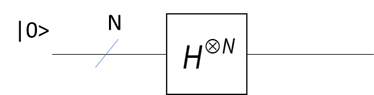

The binary-string and integer-label expressions describe the same state:

$$
|s\rangle
=\frac{1}{\sqrt n}\sum_{x=0}^{n-1}|x\rangle
=\frac{1}{\sqrt{2^N}}\sum_{x_b\in\{0,1\}^N}|x_b\rangle.
$$

## Grover search

Grover search addresses an unstructured black-box problem: among $n$ possible inputs, an oracle marks $M$ of them. The quantum query complexity is $O(\sqrt{n/M})$, compared with $O(n/M)$ classical queries for constant success probability when $M\ll n$. This is a statement about oracle calls; state preparation, reversible oracle construction, error correction, and readout must be included in an end-to-end comparison.

Define

$$\theta=\arcsin\sqrt{\frac{M}{n}}.$$

After $r$ Grover iterations the ideal success probability is

$$P_{\mathrm{good}}(r)=\sin^2\!\bigl((2r+1)\theta\bigr).$$

For the nontrivial case $0<M<n$ with known $M$, choose the nonnegative integer nearest to

$$r_*\approx \frac{\pi}{4\theta}-\frac12,$$

checking the neighboring integers if necessary. When $M\ll n$, this becomes $r_*\approx(\pi/4)\sqrt{n/M}$. Too many iterations rotate the state past the marked subspace.

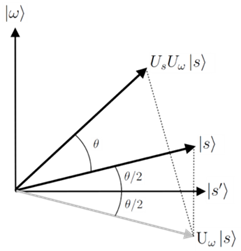

### Geometry of amplitude amplification

Assume $0<M<n$; the cases $M=0$ and $M=n$ are trivial. Let $G$ and $B$ be the marked and unmarked sets, and define normalized states

$$
|G\rangle=\frac1{\sqrt M}\sum_{x\in G}|x\rangle,
\qquad
|B\rangle=\frac1{\sqrt{n-M}}\sum_{x\in B}|x\rangle.
$$

The initial uniform state lies in their two-dimensional span:

$$|s\rangle=\sin\theta|G\rangle+\cos\theta|B\rangle,
\qquad \sin^2\theta=M/n.$$

The phase oracle $O_f=I-2\Pi_G$ reflects through the unmarked subspace. The diffusion operator $D=2|s\rangle\langle s|-I$ reflects through $|s\rangle$. Their product $DO_f$ is a rotation by $2\theta$, yielding the success formula above. The familiar “inversion about the mean” description is the computational-basis form of this reflection.

For unknown $M$, repeatedly applying a fixed iteration count can overshoot. Algorithms with randomized iteration schedules or quantum counting handle this case; if $M=0$, no sequence of Grover rotations can produce a marked outcome.

### Oracles and hidden implementation cost

A Boolean oracle must be reversible. Its standard form is

$$U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle.$$

Preparing the target in $|{-}\rangle=(|0\rangle-|1\rangle)/\sqrt2$ gives phase kickback,

$$U_f|x\rangle|{-}\rangle=(-1)^{f(x)}|x\rangle|{-}\rangle,$$

which realizes Grover's phase oracle. A practical oracle must reversibly compute the predicate, uncompute temporary workspace, and expose no residual “which-path” information. Its Toffoli count, depth, ancillas, connectivity, and data-access cost may dominate the search.

The three-qubit example below marks $|101\rangle$ and $|110\rangle$. Here $n=8$, $M=2$, and $\theta=\pi/6$, so one Grover iteration is optimal. Qiskit displays bit strings with the highest-index qubit on the left; the circuit comments use that convention.

### Grover iteration circuit

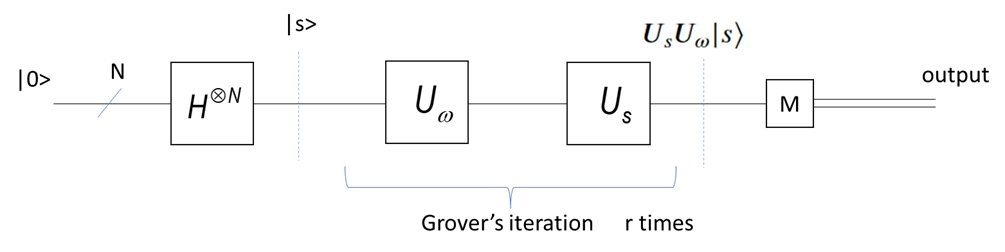

*The register is placed in a uniform superposition by $H^{\otimes N}$, then the oracle $U_\omega$ and diffusion operator $U_s$ are repeated before measurement.*


### Qiskit example

In [33]:
qr = QuantumRegister(3)  # Initialize qubits
cr = ClassicalRegister(3)  # Initialize bits for record measurements
circuitGrov = QuantumCircuit(qr, cr)

circuitGrov.draw('mpl')

<Figure size 180.31x367.889 with 1 Axes>

In [34]:
# We want to search two marked states
# |101> and |110>

# Apply Hadamard to all qubits
circuitGrov.h(qr)
circuitGrov.barrier()

circuitGrov.draw('mpl')

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q1"), index=0>, <Qubit register=(3, "q1"), index=1>, <Qubit register=(3, "q1"), index=2>), clbits=())

<Figure size 305.727x367.889 with 1 Axes>

In [35]:
# Phase oracle (Marks states |101> and |110> as results)
circuitGrov.cz(qr[2], qr[0])
circuitGrov.cz(qr[2], qr[1])

circuitGrov.draw('mpl')

<Figure size 472.949x367.889 with 1 Axes>

In [36]:
# Inversion about the average (diffusion operator)
circuitGrov.h(qr)
circuitGrov.x(qr)
circuitGrov.barrier()
circuitGrov.h(qr[2])
circuitGrov.ccx(qr[0], qr[1], qr[2])
circuitGrov.h(qr[2])
circuitGrov.barrier()
circuitGrov.x(qr)
circuitGrov.h(qr)

circuitGrov.draw('mpl')

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q1"), index=0>, <Qubit register=(3, "q1"), index=1>, <Qubit register=(3, "q1"), index=2>), clbits=())

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q1"), index=0>, <Qubit register=(3, "q1"), index=1>, <Qubit register=(3, "q1"), index=2>), clbits=())

<Figure size 1225.45x367.889 with 1 Axes>

In [37]:
# Measure
circuitGrov.measure(qr, cr)

circuitGrov.draw('mpl')

<Figure size 1476.28x367.889 with 1 Axes>

In [38]:
# Run the circuit with a local Aer simulator.
backend = AerSimulator()
compiled_grover = transpile(circuitGrov, backend, seed_transpiler=123)
grover_result = backend.run(
    compiled_grover,
    shots=1024,
    seed_simulator=123,
).result()
grover_counts = grover_result.get_counts(compiled_grover)
print(grover_counts)
plot_histogram(grover_counts)

{'110': 536, '101': 488}


<Figure size 640x480 with 1 Axes>

## Key takeaways

- The teleportation identity exposes four measurement branches and the Pauli correction required in each branch.
- A credible teleportation claim reports conditional fidelity and compares it with an appropriate classical benchmark.
- Grover iterations rotate amplitude toward the marked subspace, with the best integer count chosen near the continuous optimum.
- Query complexity counts oracle calls; an end-to-end resource estimate must also count how the oracle and data access are implemented.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. W. K. Wootters and W. H. Zurek, [“A single quantum cannot be cloned”](https://doi.org/10.1038/299802a0), *Nature* **299**, 802–803 (1982).
2. C. H. Bennett *et al.*, [“Teleporting an unknown quantum state via dual classical and Einstein–Podolsky–Rosen channels”](https://doi.org/10.1103/PhysRevLett.70.1895), *Phys. Rev. Lett.* **70**, 1895–1899 (1993).
3. M. Horodecki, P. Horodecki, and R. Horodecki, [“General teleportation channel, singlet fraction, and quasidistillation”](https://doi.org/10.1103/PhysRevA.60.1888), *Phys. Rev. A* **60**, 1888–1898 (1999).
4. L. K. Grover, [“A fast quantum mechanical algorithm for database search”](https://doi.org/10.1145/237814.237866), STOC '96, 212–219 (1996).
5. G. Brassard, P. Høyer, M. Mosca, and A. Tapp, [“Quantum amplitude amplification and estimation”](https://doi.org/10.1090/conm/305/05215), *Contemporary Mathematics* **305**, 53–74 (2002).
6. C. H. Bennett, E. Bernstein, G. Brassard, and U. Vazirani, [“Strengths and weaknesses of quantum computing”](https://doi.org/10.1137/S0097539796300933), *SIAM J. Comput.* **26**, 1510–1523 (1997).
7. IBM Quantum, [Classical feed-forward and control flow](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow).
8. IBM Quantum, [Grover's algorithm tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm).